In [38]:
import numpy as np
import pandas as pd
import markdown
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb


from pathlib import Path
import sys

sys.path.append(str(Path.cwd().parent))

from src.models.train import load_data, analysis_target, identify_columns, split_data, save_splitted_test_data, get_models,save_selected_models, save_predicted_prob_value
from src.models.predict import run_prediction,get_score,get_feature_importance 
# from src.models.evaluate import run_evaluation
from src.visualization.visualize import plot_count, plot_heatmap,plot_box, plot_bar_with_thredshold, plot_score_comparison_chart

sys.path.append('..')

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. Load Preprocessed Data

In [2]:
df = load_data()
df.head(3)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0


# 2. Univariate Analysis - Target Variable
Since we need to predict whether machine is going to fail, variable 'Machine failure' variables would be our target variable.

In [3]:
target = 'Machine failure'
print(f'Unique value of target variable {target}: {df[target].unique()}')

Unique value of target variable Machine failure: [0 1]


After target variable is determined, I have investigated target problem type.

Depending on the type of machine learning problem, I decided to examine the target variable's distribution to determine whether class imbalance exists.

The target variable was analyzed by examining class counts, proportions, and visualizing the distribution using a count plot. The results indicate a moderately imbalanced dataset, which informed the choice of evaluation metrics and modeling approach.

In [4]:
# Examine target analysis and get recommended model
analysis_target(df, target)

Machine Learning/Target Problem Type: classification
Target Class Machine failure Distribution Ratio: 0.97
Class Imbalance Detected.
Recommended Model: 
- XGBoost or LightGBM with class weights or SMOTE
- RandomForestClassifier with `class_weight='balanced'`


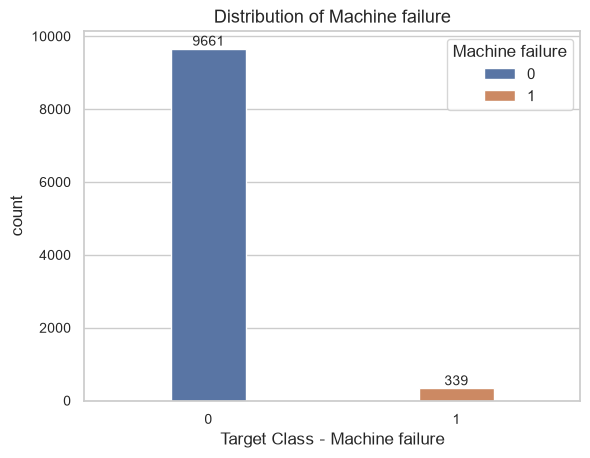

In [5]:
# Plot target distribution
plot_count(df=df,target=target,xlabel=f"Target Class - {target}",title=f"Distribution of {target}")

# 3. Correlation Analysis
## 3.1 Identify column data type
First, we drop 'UDI' and 'Product ID' column as it is just an unit identifier for each record and it could not give us useful information in exploratory analysis and classification.

Numerical and categorical features are listed to make the exploratory analysis easier and more organized.

In [6]:
# unit identifier columns
identifier_cols = ['UDI','Product ID']
# five process failure modes
failure_mode_cols = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF'] 

cat_cols, num_cols = identify_columns(target= target, df= df, id_cols= identifier_cols, fmode_cols= failure_mode_cols)

Categorical Columns: ['Type']
Numerical Columns: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


## 3.2 Numerical variables Vs Target
As the target implementation in this phase is binary classification, it is essential to understand the relationship between the features and the target variable, 'Machine failure'.

The heatmap indicates a moderate positive linear relationship between the target variable, 'Machine failure', and both 'Torque' and 'Tool wear'. In contrast, 'Air temperature' and 'Process temperature' exhibit very weak positive linear relationships with the target variable. 'Rotational speed', however, shows a moderate negative linear relationship with 'Machine failure', suggesting that higher rotational speeds may be associated with a lower likelihood of machine failure or, conversely, better machine operation.

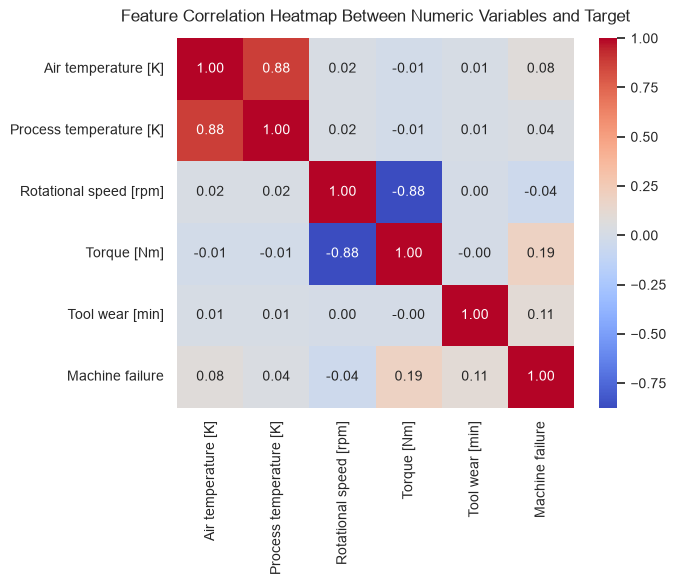

In [7]:
# plot heatmap to understand the feature correlation heatmap between numeric variables and target
title = "Feature Correlation Heatmap Between Numeric Variables and Target"
plot_heatmap(df= df, num_cols= num_cols,target=target, title= title)

To further investigate the relationship between Air temperature, Process temperature, Rotational speed, Torque, Tool wear and our target variable Machine failure, I choose to make boxplot to compare median and spread of each feature against with Machine failure.

According to the boxplots for each feature, machine with air temperature ranging from 290K to 300K, Tool wear ranging from 50min to 150min and Rotational speed ranging from 1500rpm to 1600rpm tend to be less failure. Machine with higher process temperature ranging from 310K to 311K and Tool we

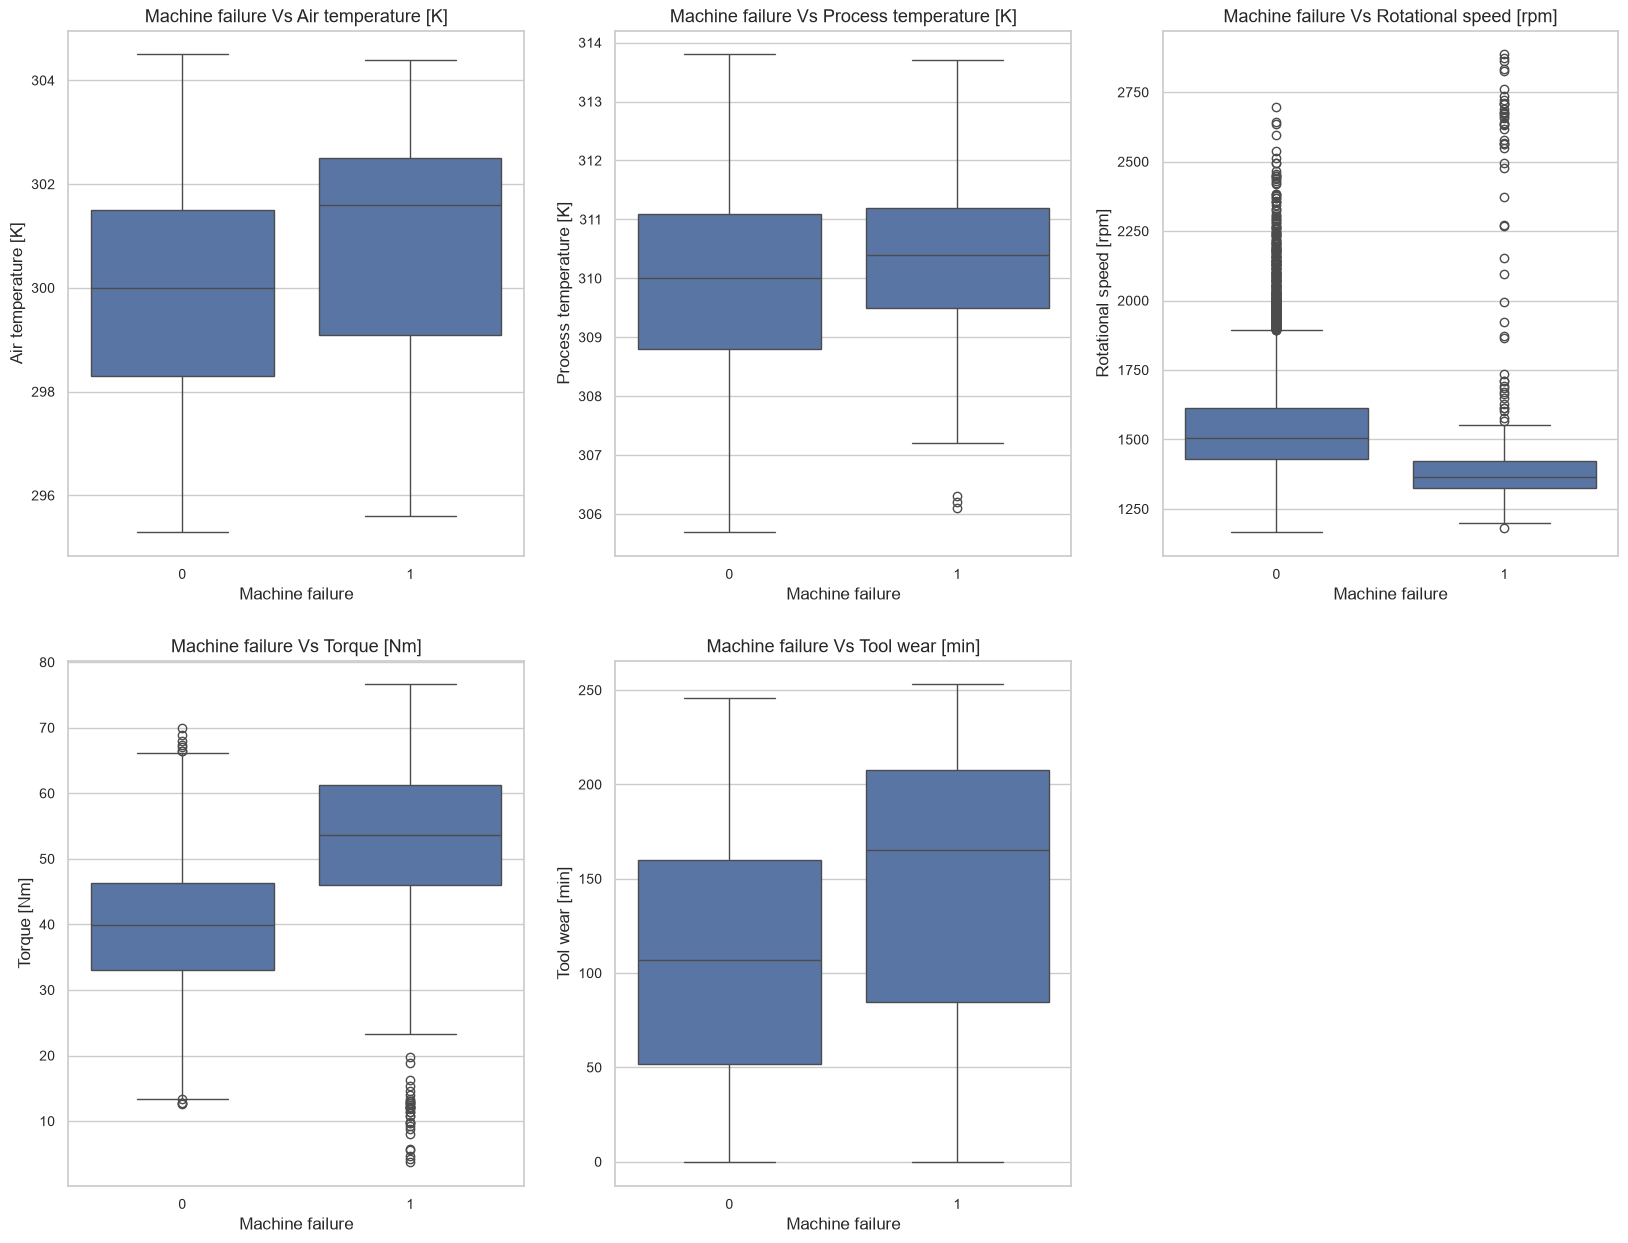

In [8]:
# plot box to understand the spread of all features against with target
plot_box(df= df, num_cols= num_cols, target= target)

## 3.3 Categorical variables Vs Target
As observed in the bar plot below, Type L machines appear more likely to operate properly compared with the other machine types. However, since the dataset is imbalanced, relying heavily on the 'Type' feature may lead to misleading accuracy and potentially inaccurate conclusions during the analysis.

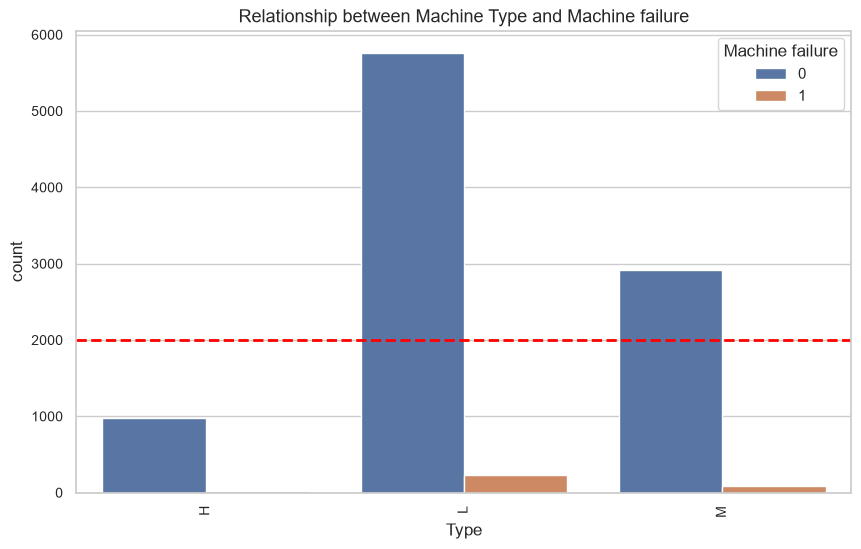

In [9]:
title = 'Relationship between Machine Type and Machine failure'
plot_bar_with_thredshold(df= df, cat_col_name= cat_cols[0], target=target,title=title)

# 4. Model Fitting and Evaluation
As the dataset exhibits class imbalance, accuracy may provide a misleading assessment of model performance. Therefore, PR-AUC (Precision-Recall Area Under the Curve) is considered a more appropriate evaluation metric, as it provides a better indication of the model's ability to identify the minority class compared with individual metrics such as Precision, Recall, and F1-Score.

## 4.1 Data Preparation for Modelling

To enable modelling, I choose variables - 'Type', 'Air temperature [K]', 'Process temperature [K]','Rotational speed [rpm]', 'Torque [Nm]',
'Tool wear [min]' as features and 'Machine failure' as target variable.

As the target class is highly imbalanced, with a ratio of 0.97, I decided to maintain the class distribution in both the training and test datasets by using the stratify argument.

## 4.2 Select Features

In [10]:
num_feature = num_cols
cat_feature = cat_cols
print(f"numeric features : {num_feature}")
print(f"categorical features : {cat_feature}")

numeric features : ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
categorical features : ['Type']


## 4.3 Split data to define test set

In [56]:

# split data
splitted_data = split_data(df= df,
                    target= target,
                    test_size=0.2,
                    cat_cols= cat_cols,
                    num_cols= num_cols)

list(splitted_data.keys())


['X_train', 'X_test', 'y_train', 'y_test']

In [57]:
# save splitted data
save_splitted_test_data(X_train= splitted_data['X_train'],
                        X_test= splitted_data['X_test'],
                        y_train= splitted_data['y_train'],
                        y_test=splitted_data['y_test'])

Test dataset is successfully saved.


# 5. Model Training
- Base Model : XGBoost
- Compare Model : Light GBM
- Compare Model 2 : RandomForest Classifier

In [ ]:
# get all models
model_pipelines  = get_models(num_feature= num_feature,
           cat_feature= cat_feature,
           X_train= splitted_data['X_train'],
           y_train= splitted_data['y_train'])

In [59]:
mdl_pipeline_xgb, mdl_pipeline_lgb, mdl_pipeline_rdf = model_pipelines

In [60]:
print(f"XGBoost : {mdl_pipeline_xgb}")

XGBoost : {'model': 'XGBoost', 'pipeline': Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Type'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_byle...
                              

In [61]:
print(f"Light GBM : {mdl_pipeline_lgb}")

Light GBM : {'model': 'LightGBM', 'pipeline': Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Type'])])),
                ('classifier',
                 LGBMClassifier(max_depth=5, n_estimators=200,
                                objective='binary', random_state=42,
                      

In [62]:
print(f"XGBoost : {mdl_pipeline_rdf}")

XGBoost : {'model': 'RandomForestClassifier', 'pipeline': Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Type'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=7,
                                        n_estimators=200, n_jobs

# 6. Model Prediction and Scoring

In [79]:
# XGBoost model prediction and scoring
pred_result_xgb = run_prediction(model= mdl_pipeline_xgb['pipeline'], 
                        X_test=splitted_data['X_test'])

pr_auc_xgb = get_score(y_test=splitted_data['y_test'], 
                       y_prob=pred_result_xgb['y_prob'])

print(f"PR_AUC: {pr_auc_xgb}")
print(f"predicted result: {pred_result_xgb}")


PR_AUC: 0.832
predicted result: {'y_pred': array([0, 0, 0, ..., 0, 0, 0], shape=(2000,)), 'y_prob': array([3.4209065e-02, 1.0067204e-04, 4.6902299e-02, ..., 6.4241023e-05,
       1.0148223e-03, 6.9303736e-05], shape=(2000,), dtype=float32)}


In [80]:
# Light GBM model prediction and scoring
pred_result_lgb = run_prediction(model = mdl_pipeline_lgb['pipeline'], 
                                       X_test=splitted_data['X_test'])

pr_auc_lgb = get_score(y_test= splitted_data['y_test'], 
                       y_prob= pred_result_lgb['y_prob'])

print(f"PR_AUC: {pr_auc_lgb}")
print(f"predicted result: {pred_result_lgb}")


PR_AUC: 0.827
predicted result: {'y_pred': array([0, 0, 0, ..., 0, 0, 0], shape=(2000,)), 'y_prob': array([2.61042549e-01, 3.83838048e-04, 2.09076008e-01, ...,
       2.91877404e-04, 1.04081786e-02, 8.62667885e-05], shape=(2000,))}


d:\All Practice Projects\Git Hub Projects\Machine-Failure-Prediction\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
d:\All Practice Projects\Git Hub Projects\Machine-Failure-Prediction\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [81]:
# Random Forest regressor model prediction
pred_result_rdf = run_prediction(model= mdl_pipeline_rdf['pipeline'],
                                         X_test=splitted_data['X_test'])

pr_auc_rdf = get_score(y_test=splitted_data['y_test'], 
                       y_prob=pred_result_rdf['y_prob'])


print(f"PR_AUC: {pr_auc_rdf}")
print(f"predicted result: {pred_result_rdf}")

PR_AUC: 0.6
predicted result: {'y_pred': array([1, 0, 1, ..., 0, 0, 0], shape=(2000,)), 'y_prob': array([0.77177028, 0.05591817, 0.51846587, ..., 0.04298323, 0.22817311,
       0.0457373 ], shape=(2000,))}


# 7. Score Comparison

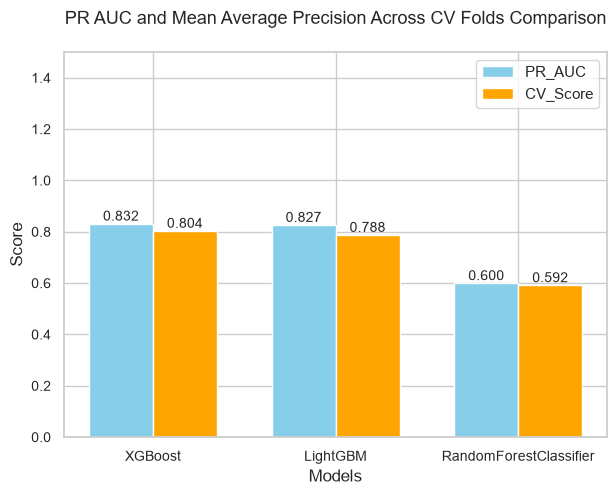

In [82]:
model_list = [ mdl_pipeline_xgb['model'], mdl_pipeline_lgb['model'], mdl_pipeline_rdf['model']]
pr_auc_list = [pr_auc_xgb, pr_auc_lgb, pr_auc_rdf]
cv_score_list = [mdl_pipeline_xgb['best_score'], mdl_pipeline_lgb['best_score'], mdl_pipeline_rdf['best_score']]

plot_score_comparison_chart(model_list=model_list,pr_auc_list=pr_auc_list, cv_score_list= cv_score_list)

Based on the comparison, the two best-performing models are **XGBoost** and **LightGBM**. 

**XGBoost** achieves the highest performance, with a PR-AUC of 0.832 and a CV score of 0.804, indicating strong predictive performance and consistency across cross-validation folds. 

**LightGBM** ranks second, with a PR-AUC of 0.827 and a CV score of 0.788.

# 8. Finding the Feature Importance of Finalist Models
I extract features names from the preprocessing steps to get feature importance.

## 8.1 Feature Importance in XGBoost Classifier

                   feature  Importance
2   Rotational speed [rpm]    0.340118
3              Torque [Nm]    0.263031
4          Tool wear [min]    0.211843
0      Air temperature [K]    0.052512
6                   Type_L    0.044344
1  Process temperature [K]    0.043377
7                   Type_M    0.026124
5                   Type_H    0.018652


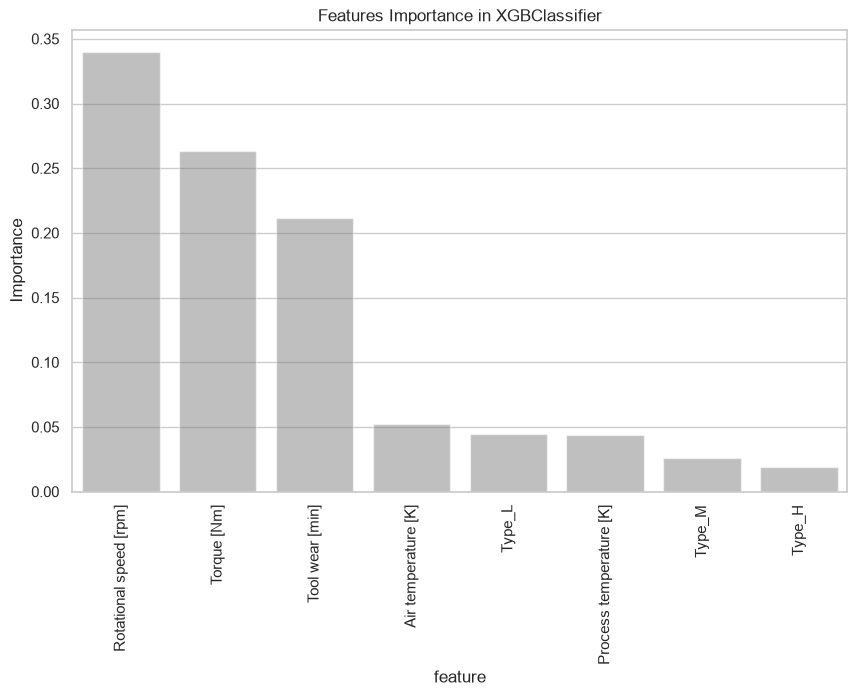

In [84]:
feature_importances_xgb  = get_feature_importance(pipeline = mdl_pipeline_xgb['pipeline'])

## 8.2 Feature Importance in LightGBM

                   feature  Importance
4          Tool wear [min]         809
3              Torque [Nm]         783
2   Rotational speed [rpm]         612
0      Air temperature [K]         501
1  Process temperature [K]         493
6                   Type_L          51
7                   Type_M          42
5                   Type_H          22


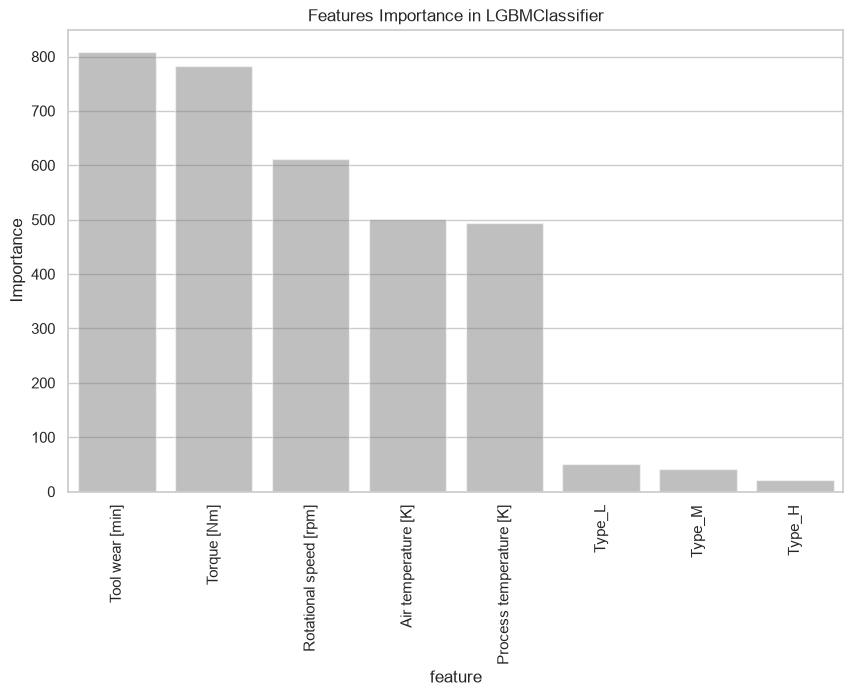

In [85]:
feature_importances_lgb = get_feature_importance(pipeline = mdl_pipeline_lgb['pipeline'])

## 8.3 Importance Features

In [86]:
top_feature_xgb = pd.DataFrame(
    {'Model': mdl_pipeline_xgb['model'], 
     'Feature':feature_importances_xgb.iloc[:3]['feature'] }
    )

top_feature_lgb = pd.DataFrame(
    {'Model': mdl_pipeline_lgb['model'], 
     'Feature':feature_importances_lgb.iloc[:3]['feature'] }
     )

all_imp_features = pd.concat([top_feature_xgb, top_feature_lgb])

print(all_imp_features.to_markdown())

|    | Model    | Feature                |
|---:|:---------|:-----------------------|
|  2 | XGBoost  | Rotational speed [rpm] |
|  3 | XGBoost  | Torque [Nm]            |
|  4 | XGBoost  | Tool wear [min]        |
|  4 | LightGBM | Tool wear [min]        |
|  3 | LightGBM | Torque [Nm]            |
|  2 | LightGBM | Rotational speed [rpm] |


## 8.4 Save All Finalist Models and Prediction

In [87]:
# save model for SLA evaluation
seleted_model_pipelines = [mdl_pipeline_xgb, mdl_pipeline_lgb]
save_selected_models(seleted_model_pipelines)


Models successfully saved.


In [90]:
# save predicted value of finalist model
selected_model_result = [{'model_name': mdl_pipeline_xgb['model'] , 'y_pred' : pred_result_xgb['y_pred']}, 
                         {'model_name' : mdl_pipeline_lgb['model'], 'y_pred': pred_result_lgb['y_pred']}
                         ]

save_predicted_prob_value(lst_model_result = selected_model_result)


Predicted value successfully saved.
